# SVM and K-Fold Cross Validation

In [1]:
import numpy as np
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn import datasets
from sklearn import svm

iris = datasets.load_iris()


A single train/test split is made easy with the train_test_split function in the cross_validation library:

In [2]:
# Split the iris data into train/test data sets with 40% reserved for testing
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.4, random_state=0)

# Build an SVC model for predicting iris classifications using training data
clf = svm.SVC(kernel='linear').fit(X_train, y_train)

# Now measure its performance(accuracy) with the test data
clf.score(X_test, y_test)   

0.9666666666666667

K-Fold cross validation is just as easy; let's use a K of 5:

In [3]:
# We give cross_val_score a model, the entire data set and its "real" values, and the number of folds:
scores = cross_val_score(clf, iris.data, iris.target, cv=5)

# Print the accuracy for each fold:
print(scores)

# And the mean accuracy of all 5 folds:
print(scores.mean())

[0.96666667 1.         0.96666667 0.96666667 1.        ]
0.9800000000000001


Our model is even better than we thought! Can we do better? Let's try a different kernel (poly):

In [4]:
clf = svm.SVC(kernel='poly')
scores = cross_val_score(clf, iris.data, iris.target, cv=5)
print(scores)
print(scores.mean())

[0.96666667 1.         0.96666667 0.96666667 1.        ]
0.9800000000000001


what conclusions can you draw from the results?

In [5]:
# Build an SVC model for predicting iris classifications using training data
clf = svm.SVC(kernel='poly').fit(X_train, y_train)

# Now measure its performance with the test data
clf.score(X_test, y_test)   

0.9

#### Conclusions

- **Un seul découpage est trompeur** : avec `train_test_split` (60/40) le modèle linéaire obtient 96.7 %, alors que la validation croisée à 5 plis donne **98 %** (scores par pli : 0.967, 1, 0.967, 0.967, 1). La VC utilise tous les exemples à la fois pour l'entraînement et le test, et sa moyenne est plus fiable qu'un seul score.
- **Noyau linéaire et noyau `poly` (degré 3 par défaut)** ont exactement les mêmes scores en VC (98 %), car l'iris est presque linéairement séparable : un noyau plus flexible n'apporte rien.
- Par contre, sur le découpage unique, `poly` ne fait que **90 %** contre 96.7 % pour le linéaire : un modèle plus complexe (degré 3) s'ajuste plus au jeu d'entraînement, d'où un soupçon de **surapprentissage** que l'on teste dans l'activité.

## Activity

- What are your remarks about using a Linear kernel versus using a non-linear kernel ?
- The "poly" kernel for SVC actually has another attribute for the number of degrees of the polynomial used, which defaults to 3. For example, svm.SVC(kernel='poly', degree=3). We think the default third-degree polynomial is overfitting, based on the results above. But how about 2? Give that a try and compare it to the linear kernel.

### Activité 1 — Noyau linéaire vs noyaux non linéaires

On compare plusieurs noyaux avec la même validation croisée à 5 plis, puis avec une **validation croisée répétée** (5 plis × 10 répétitions, graines différentes) pour obtenir une estimation plus stable : sur 150 fleurs seulement, un seul découpage est très bruité.

In [6]:
import pandas as pd, time
from sklearn.model_selection import RepeatedStratifiedKFold

X, y = iris.data, iris.target
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)

models = {
 'linear'          : svm.SVC(kernel='linear'),
 'poly (degré 2)'  : svm.SVC(kernel='poly', degree=2),
 'poly (degré 3, défaut)': svm.SVC(kernel='poly', degree=3),
 'poly (degré 4)'  : svm.SVC(kernel='poly', degree=4),
 'rbf'             : svm.SVC(kernel='rbf'),
 'sigmoid'         : svm.SVC(kernel='sigmoid'),
}
rows = []
for name, m in models.items():
    s5  = cross_val_score(m, X, y, cv=5)
    srep = cross_val_score(m, X, y, cv=rcv)
    m.fit(X_train, y_train)
    rows.append(dict(noyau=name, **{'CV-5 (moy)': s5.mean(), 'CV-5 (écart-type)': s5.std(),
                                    'CV répétée (moy)': srep.mean(), 'CV répétée (écart-type)': srep.std(),
                                    'train (60 %)': m.score(X_train, y_train), 'test (40 %)': m.score(X_test, y_test)}))
res = pd.DataFrame(rows).set_index('noyau')
display((res*100).round(2))

,CV-5 (moy),CV-5 (écart-type),CV répétée (moy),CV répétée (écart-type),train (60 %),test (40 %)
noyau,,,,,,
linear,98.00,1.63,97.73,2.86,98.89,96.67
poly (degré 2),98.67,1.63,97.33,3.13,98.89,95.00
"poly (degré 3, défaut)",98.00,1.63,96.00,3.46,98.89,90.00
poly (degré 4),96.67,4.22,96.27,3.57,98.89,91.67
rbf,96.67,2.11,96.27,3.17,97.78,93.33
sigmoid,6.67,5.96,6.87,3.43,37.78,26.67


### Activité 2 — Polynôme de degré 2 vs noyau linéaire

Comparaison directe, fold par fold, du noyau `poly` de degré 2 (demandé dans l'énoncé) avec le noyau linéaire, puis avec le degré 3 par défaut.

In [7]:
for name, m in [('linear', svm.SVC(kernel='linear')),
                ('poly degré 2', svm.SVC(kernel='poly', degree=2)),
                ('poly degré 3 (défaut)', svm.SVC(kernel='poly', degree=3))]:
    s = cross_val_score(m, X, y, cv=5)
    print('%-24s scores par pli = %s | moyenne = %.4f' % (name, np.round(s, 3), s.mean()))

linear                   scores par pli = [0.967 1.    0.967 0.967 1.   ] | moyenne = 0.9800
poly degré 2             scores par pli = [0.967 1.    1.    0.967 1.   ] | moyenne = 0.9867
poly degré 3 (défaut)    scores par pli = [0.967 1.    0.967 0.967 1.   ] | moyenne = 0.9800


On regarde aussi **l'effet du degré** (1 à 8) sur l'accuracy en entraînement et en validation croisée, pour voir où commence le surapprentissage.

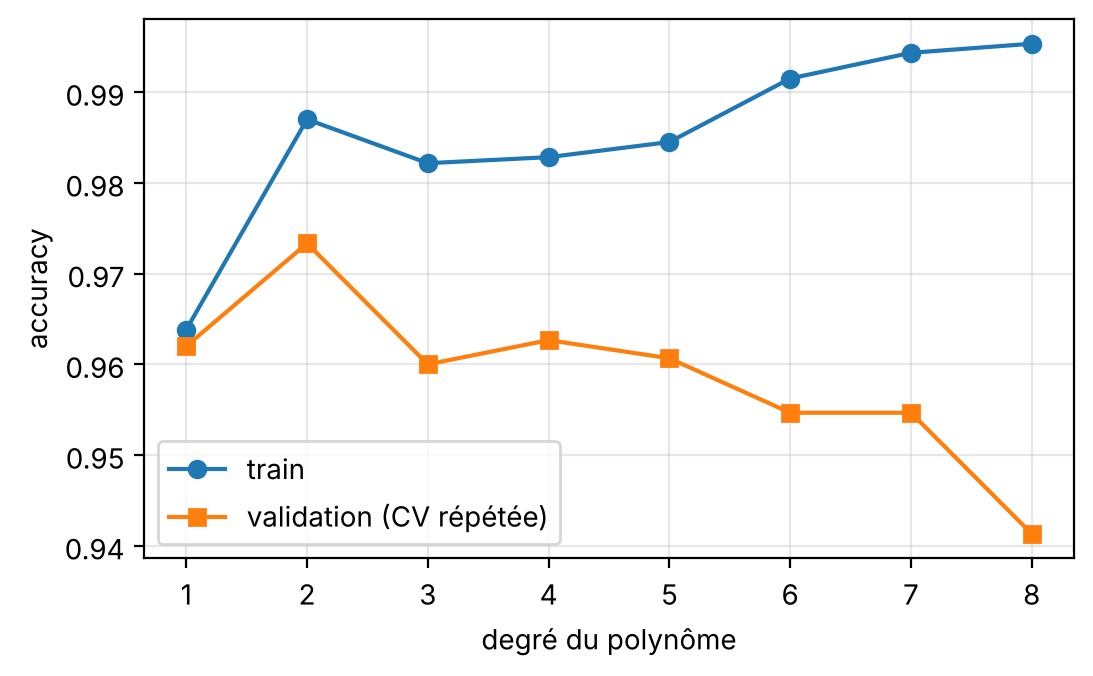

    train  validation
1  0.9638      0.9620
2  0.9870      0.9733
3  0.9822      0.9600
4  0.9828      0.9627
5  0.9845      0.9607
6  0.9915      0.9547
7  0.9943      0.9547
8  0.9953      0.9413


In [8]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
degs = range(1, 9)
tr, va = [], []
for d in degs:
    r = cross_validate(svm.SVC(kernel='poly', degree=d), X, y, cv=rcv, return_train_score=True)
    tr.append(r['train_score'].mean()); va.append(r['test_score'].mean())
plt.figure(figsize=(6, 3.5))
plt.plot(degs, tr, 'o-', label='train'); plt.plot(degs, va, 's-', label='validation (CV répétée)')
plt.xlabel('degré du polynôme'); plt.ylabel('accuracy'); plt.legend(); plt.grid(alpha=.3); plt.show()
print(pd.DataFrame({'train': np.round(tr, 4), 'validation': np.round(va, 4)}, index=list(degs)))

#### Remarques

**1. Linéaire vs non linéaire** : sur l'iris, les noyaux non linéaires **n'améliorent pas** le résultat. Avec une VC répétée (50 découpages), le noyau linéaire est le meilleur (97.7 %) devant `poly` degré 2 (97.3 %), `rbf` et `poly` degré 4 (≈ 96.3 %), `poly` degré 3 (96 %). Les classes sont presque séparables par des hyperplans, donc un noyau plus complexe ajoute de la flexibilité inutile et un risque de surapprentissage. Règle pratique : tester d'abord le linéaire, qui est le plus simple, le plus rapide et le plus interprétable.

**2. Poly degré 2 vs linéaire** : sur la VC 5 plis, le degré 2 donne **98.67 %** contre 98.0 % pour le linéaire, ce qui correspond à **un seul exemple de plus bien classé sur 150**. La VC répétée donne l'inverse (97.3 % contre 97.7 %), avec un écart-type d'environ 3 points : la différence **n'est pas significative**. En revanche, l'hypothèse de l'énoncé est confirmée : le degré 2 vaut mieux que le degré 3 par défaut (98.67 % contre 98.0 % en VC 5 plis ; 97.3 % contre 96.0 % en VC répétée).

**3. Effet du degré** : l'accuracy d'entraînement **augmente** avec le degré (96.4 % → 99.5 %) alors que l'accuracy de validation **atteint son maximum au degré 2** (97.3 %) puis **chute** (94.1 % au degré 8) : l'écart grandissant entre les deux courbes est le signe classique du **surapprentissage**.

**4. Le noyau `sigmoid` échoue totalement** (≈ 7 % d'accuracy, soit **moins que le hasard**, 33 %) : les variables ne sont pas normalisées, ce qui sature la fonction `tanh`, et le noyau sigmoïde n'est de plus pas un noyau défini positif en général. Avec ce noyau, les données devraient être standardisées et `gamma`/`coef0` ajustés.